# 04 · Optimiser les hyperparamètres

**Étape 7** du cas pratique · Slides 24, 29, 45–51.

On règle les deux candidats de l'étape 6 : **LightGBM natif** (rapide, il surapprend par défaut : grande marge de réglage) et **CatBoost natif** (le meilleur par défaut, mais lent). Même métrique (PR-AUC), même objet `CV` (5 plis), budget de **40 essais** par recherche. Le test reste scellé.

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # barre de progression d'Optuna

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 (import expérimental)
from sklearn.model_selection import (HalvingRandomSearchCV, RandomizedSearchCV, StratifiedKFold,
                                     cross_val_score)

from financial_inclusion_africa import config, models, viz
from financial_inclusion_africa.data import load_split
from financial_inclusion_africa.evaluate import CV, evaluate_cv, fold_scores, format_summary, paired_difference
from financial_inclusion_africa.features import catboost_cat_features, pipe

viz.set_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)
RS = config.RANDOM_STATE
X_train, X_test, y_train, y_test = load_split()  # X_test : non utilisé avant l'étape 10

## Étape 7 · Optimiser les hyperparamètres

### Référence : les réglages par défaut de l'étape 6

On réévalue ici, sur les mêmes plis, le modèle de base et les deux candidats avec leurs réglages par défaut : c'est par rapport à eux qu'on mesure le gain du réglage (Q7.2).

In [2]:
defaults = {
    "Régression logistique (modèle de base)": models.make_baseline(),
    "LightGBM · défaut": pipe(LGBMClassifier(random_state=RS, verbose=-1, n_jobs=1), encoding="native"),
    "CatBoost · défaut": pipe(CatBoostClassifier(cat_features=catboost_cat_features(), random_seed=RS,
                                                 thread_count=models.CATBOOST_THREADS, verbose=0), encoding="native_str"),
}
rows, res = [], {}
for name, model in defaults.items():
    row, res[name] = evaluate_cv(model, X_train, y_train, name=name)
    rows.append(row)
format_summary(pd.DataFrame(rows), metrics=["pr_auc", "roc_auc", "brier", "logloss"])

,pr_auc,roc_auc,brier,logloss,temps (s)
Régression logistique (modèle de base),0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.23
LightGBM · défaut,0.564 ± 0.023,0.854 ± 0.010,0.086 ± 0.003,0.290 ± 0.010,0.25
CatBoost · défaut,0.581 ± 0.026,0.863 ± 0.010,0.084 ± 0.003,0.283 ± 0.009,19.71


### 7.1 Random Search (LightGBM)

Espace du guide ; `RandomizedSearchCV` tire 40 configurations au hasard et les évalue toutes sur `CV`. Le pipeline utilise l'encodage natif (`encoding="native"`), d'où le préfixe `lgbmclassifier__`.

> Le guide règle `n_estimators` comme les autres hyperparamètres. La slide 51 recommande plutôt un grand nombre d'arbres avec **arrêt anticipé** ; on suit ici le guide, pour comparer Random Search et Optuna sur le même espace.

In [3]:
space = {
    "lgbmclassifier__learning_rate": loguniform(1e-3, 0.3),
    "lgbmclassifier__num_leaves": randint(4, 64),
    "lgbmclassifier__min_child_samples": randint(5, 200),
    "lgbmclassifier__subsample": uniform(0.5, 0.5),  # entre 0,5 et 1
    "lgbmclassifier__subsample_freq": [1],
    "lgbmclassifier__colsample_bytree": uniform(0.5, 0.5),
    "lgbmclassifier__reg_lambda": loguniform(1e-3, 10),
    "lgbmclassifier__n_estimators": randint(100, 600),
}
lgbm_base = pipe(LGBMClassifier(random_state=RS, verbose=-1, n_jobs=1), encoding="native")

t0 = time.time()
rs = RandomizedSearchCV(lgbm_base, space, n_iter=40, cv=CV, scoring="average_precision",
                        random_state=RS, n_jobs=-1, return_train_score=True)
rs.fit(X_train, y_train)
time_rs = time.time() - t0
print(f"Random Search : {time_rs:.0f} s · meilleure PR-AUC {rs.best_score_:.4f} "
      f"(± {rs.cv_results_['std_test_score'][rs.best_index_]:.4f})")
pd.Series({k.removeprefix("lgbmclassifier__"): v for k, v in rs.best_params_.items()}, name="meilleure configuration").to_frame()

Random Search : 51 s · meilleure PR-AUC 0.5793 (± 0.0252)


,meilleure configuration
colsample_bytree,0.921142
learning_rate,0.013005
min_child_samples,194.000000
n_estimators,583.000000
num_leaves,17.000000
reg_lambda,0.811125
subsample,0.663270
subsample_freq,1.000000


In [4]:
# Les 5 meilleures configurations sur 40
top = pd.DataFrame(rs.cv_results_).sort_values("rank_test_score").head(5)
cols = [c for c in top.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "mean_train_score"]
top[cols].rename(columns=lambda c: c.removeprefix("param_lgbmclassifier__")).round(4)

,colsample_bytree,learning_rate,min_child_samples,n_estimators,num_leaves,reg_lambda,subsample,subsample_freq,mean_test_score,std_test_score,mean_train_score
9,0.9211,0.0130,194,583,17,0.8111,0.6633,1,0.5793,0.0252,0.6288
10,0.7852,0.0195,194,395,24,0.0359,0.6357,1,0.5781,0.0261,0.6373
5,0.7334,0.1350,139,120,12,0.0018,0.9744,1,0.5776,0.0231,0.6459
18,0.8182,0.0060,100,487,33,0.0036,0.8022,1,0.5769,0.0280,0.6195
30,0.9048,0.0073,56,588,36,0.0389,0.7589,1,0.5765,0.0260,0.6485


### Q7.1 · Pourquoi une échelle logarithmique pour `learning_rate` et `reg_lambda` ?

,tirage uniforme,tirage log-uniforme
learning_rate,,
"0,001–0,01",31,424
"0,01–0,1",313,383
"0,1–0,3",656,193


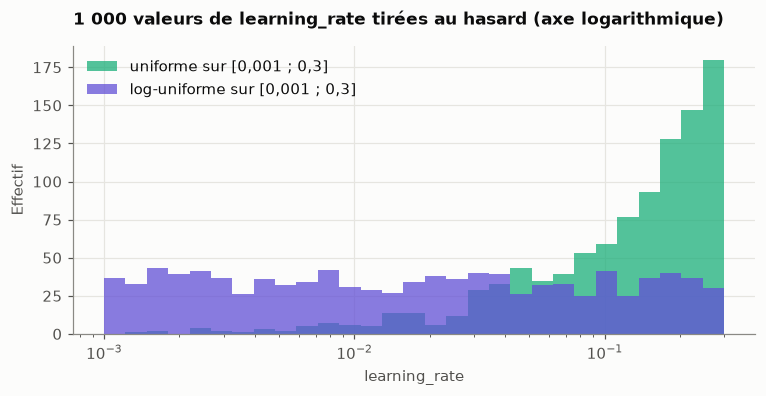

In [5]:
rng = np.random.default_rng(RS)
lin = rng.uniform(1e-3, 0.3, 1000)
log = loguniform(1e-3, 0.3).rvs(1000, random_state=RS)
decades = [1e-3, 1e-2, 1e-1, 0.3]
labels = ["0,001–0,01", "0,01–0,1", "0,1–0,3"]
counts = pd.DataFrame({
    "tirage uniforme": pd.cut(lin, decades, labels=labels).value_counts().sort_index(),
    "tirage log-uniforme": pd.cut(log, decades, labels=labels).value_counts().sort_index(),
})
display(counts.rename_axis("learning_rate"))

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(-3, np.log10(0.3), 30)
ax.hist(lin, bins=bins, alpha=0.75, color=viz.COMPOSITION[0], label="uniforme sur [0,001 ; 0,3]")
ax.hist(log, bins=bins, alpha=0.75, color=viz.COMPOSITION[1], label="log-uniforme sur [0,001 ; 0,3]")
ax.set(xscale="log", title="1 000 valeurs de learning_rate tirées au hasard (axe logarithmique)",
       xlabel="learning_rate", ylabel="Effectif")
ax.legend()
viz.save(fig, "07_echelle_log")
plt.show()

**Réponse Q7.1.** Ces hyperparamètres agissent de façon **multiplicative** : passer de 0,001 à 0,01 change autant le comportement du modèle que passer de 0,01 à 0,1 (on multiplie le pas par 10 dans les deux cas). Ce qui compte est l'**ordre de grandeur**, pas la valeur absolue.

- Un tirage **uniforme** sur [0,001 ; 0,3] gaspille le budget : 97 % des valeurs tombent entre 0,01 et 0,3, et l'intervalle [0,001 ; 0,01], où se trouvent les pas lents mais souvent précis, n'est presque jamais exploré (31 valeurs sur 1 000 ci-dessus).
- Un tirage **log-uniforme** répartit les essais **par décade**, proportionnellement à sa largeur : 424, 383 et 193 valeurs pour [0,001 ; 0,01], [0,01 ; 0,1] et [0,1 ; 0,3] (cette dernière ne couvre qu'une demi-décade). Chaque échelle est explorée (slide 51 : « log pour tout ce qui agit de façon multiplicative »).

Même logique pour `reg_lambda` (pénalité L2, de 0,001 à 10) et `min_child_samples` dans Optuna (`log=True`).

### 7.2 Optimisation bayésienne avec Optuna (TPE)

**LightGBM** : même espace que la Random Search, mêmes 40 essais. TPE (slide 48) construit un modèle des essais passés et propose les configurations les plus prometteuses.

In [6]:
def objective_lgbm(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        num_leaves=trial.suggest_int("num_leaves", 4, 64),
        min_child_samples=trial.suggest_int("min_child_samples", 5, 200, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
    )
    model = pipe(LGBMClassifier(**params, random_state=RS, verbose=-1, n_jobs=1), encoding="native")
    return cross_val_score(model, X_train, y_train, cv=CV, scoring="average_precision", n_jobs=-1).mean()

t0 = time.time()
study_lgbm = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RS))
study_lgbm.optimize(objective_lgbm, n_trials=40)
time_op_lgbm = time.time() - t0
print(f"Optuna (LightGBM) : {time_op_lgbm:.0f} s · meilleure PR-AUC {study_lgbm.best_value:.4f}")
pd.Series(study_lgbm.best_params, name="meilleure configuration").to_frame()

Optuna (LightGBM) : 44 s · meilleure PR-AUC 0.5815


,meilleure configuration
learning_rate,0.048816
num_leaves,6.000000
min_child_samples,23.000000
subsample,0.560914
colsample_bytree,0.530675
reg_lambda,1.934636
n_estimators,341.000000


**CatBoost** : un essai coûte 8 à 25 s (5 plis en parallèle), contre moins d'une seconde pour LightGBM. On ne lance donc **qu'une** recherche, avec Optuna, la plus économe en essais. Espace : pas d'apprentissage et pénalité L2 en log, profondeur des arbres symétriques de 3 à 8, nombre d'itérations, et les deux sources d'aléa de CatBoost (`bagging_temperature`, `random_strength`).

In [7]:
def objective_cat(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        depth=trial.suggest_int("depth", 3, 8),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.5, 30, log=True),
        iterations=trial.suggest_int("iterations", 200, 1000),
        bagging_temperature=trial.suggest_float("bagging_temperature", 0.0, 1.0),
        random_strength=trial.suggest_float("random_strength", 0.1, 10, log=True),
    )
    model = pipe(CatBoostClassifier(**params, cat_features=catboost_cat_features(), random_seed=RS,
                                    thread_count=models.CATBOOST_THREADS, verbose=0), encoding="native_str")
    return cross_val_score(model, X_train, y_train, cv=CV, scoring="average_precision", n_jobs=5).mean()

t0 = time.time()
study_cat = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RS))
study_cat.optimize(objective_cat, n_trials=40)
time_op_cat = time.time() - t0
print(f"Optuna (CatBoost) : {time_op_cat / 60:.1f} min · meilleure PR-AUC {study_cat.best_value:.4f}")
pd.Series(study_cat.best_params, name="meilleure configuration").to_frame()

Optuna (CatBoost) : 8.1 min · meilleure PR-AUC 0.5841


,meilleure configuration
learning_rate,0.065061
depth,4.000000
l2_leaf_reg,23.778514
iterations,801.000000
bagging_temperature,0.537534
random_strength,2.821585


In [8]:
# Les configurations retenues sont recopiées dans models.py (LGBM_PARAMS, CATBOOST_PARAMS) pour les
# notebooks 05 et 06 : on vérifie qu'elles correspondent bien aux meilleurs essais.
for study, saved in [(study_lgbm, models.LGBM_PARAMS), (study_cat, models.CATBOOST_PARAMS)]:
    for key, value in study.best_params.items():
        assert np.isclose(saved[key], value), (key, saved[key], value)
print("✓ models.py contient les meilleures configurations trouvées par Optuna")

✓ models.py contient les meilleures configurations trouvées par Optuna


### Q7.2 · Gain de chaque recherche, en nombre d'écarts-types

In [9]:
tuned = {
    "LightGBM · Random Search": pipe(LGBMClassifier(**{k.removeprefix("lgbmclassifier__"): v for k, v in rs.best_params_.items()},
                                                    random_state=RS, verbose=-1, n_jobs=1), encoding="native"),
    "LightGBM · Optuna": models.make_lgbm(),
    "CatBoost · Optuna": models.make_catboost(),
}
for name, model in tuned.items():
    row, res[name] = evaluate_cv(model, X_train, y_train, name=name)
    rows.append(row)
summary7 = pd.DataFrame(rows)

searches = {  # recherche : (configuration par défaut, temps de la recherche)
    "LightGBM · Random Search": ("LightGBM · défaut", time_rs),
    "LightGBM · Optuna": ("LightGBM · défaut", time_op_lgbm),
    "CatBoost · Optuna": ("CatBoost · défaut", time_op_cat),
}
gains = []
for name, (default, seconds) in searches.items():
    d = paired_difference(res[default], res[name])
    sd = summary7.loc[default, ("pr_auc", "val", "mean")], summary7.loc[default, ("pr_auc", "val", "std")]
    gains.append({
        "recherche": name,
        "PR-AUC par défaut": d["moyenne A"],
        "PR-AUC réglée": d["moyenne B"],
        "gain": d["différence moyenne B − A"],
        "écart-type par défaut": sd[1],
        "gain en écarts-types": d["différence moyenne B − A"] / sd[1],
        "plis gagnés": f'{d["plis où B > A"]}/5',
        "temps de la recherche (s)": seconds,
    })
gains = pd.DataFrame(gains).set_index("recherche")
gains.round(4)

,PR-AUC par défaut,PR-AUC réglée,gain,écart-type par défaut,gain en écarts-types,plis gagnés,temps de la recherche (s)
recherche,,,,,,,
LightGBM · Random Search,0.5636,0.5793,0.0157,0.0230,0.6833,5/5,50.8252
LightGBM · Optuna,0.5636,0.5815,0.0179,0.0230,0.7765,5/5,43.8819
CatBoost · Optuna,0.5815,0.5841,0.0027,0.0259,0.1028,4/5,488.0200


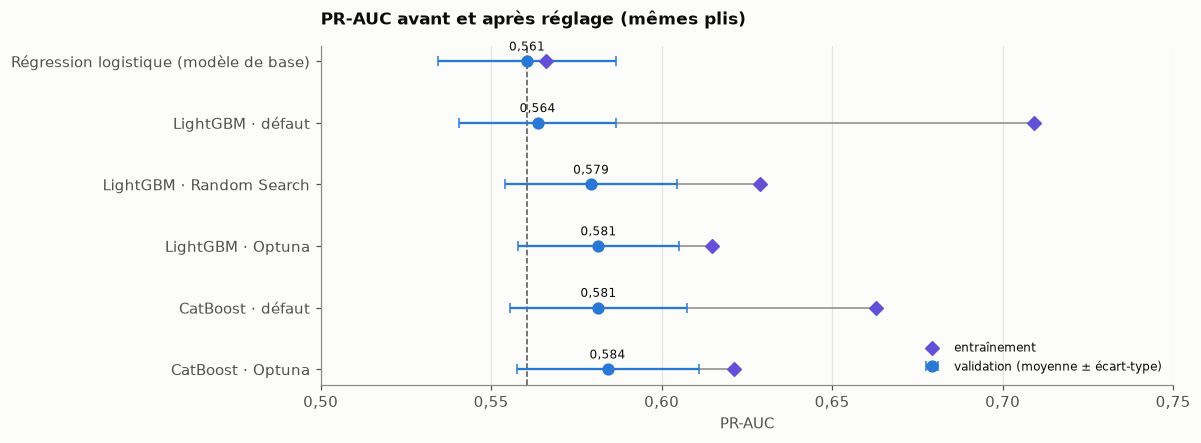

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
order7 = ["Régression logistique (modèle de base)", "LightGBM · défaut", "LightGBM · Random Search",
          "LightGBM · Optuna", "CatBoost · défaut", "CatBoost · Optuna"]
y = np.arange(len(order7))[::-1]
mean = summary7.loc[order7, ("pr_auc", "val", "mean")]
std = summary7.loc[order7, ("pr_auc", "val", "std")]
train = summary7.loc[order7, ("pr_auc", "train", "mean")]
ax.hlines(y, mean, train, color=viz.INK_3, lw=1, zorder=1)
ax.errorbar(mean, y, xerr=std, fmt="o", color=viz.YES, capsize=3, ms=7, zorder=3, label="validation (moyenne ± écart-type)")
ax.scatter(train, y, marker="D", color=viz.COMPOSITION[1], s=40, zorder=3, label="entraînement")
for yi, v in zip(y, mean):
    ax.annotate(viz.fr(f"{v:.3f}"), (v, yi), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.axvline(mean.iloc[0], color=viz.INK_2, ls="--", lw=1)
ax.set_yticks(y, order7)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fr(f"{v:.2f}")))
ax.set(title="PR-AUC avant et après réglage (mêmes plis)", xlabel="PR-AUC", xlim=(0.5, 0.75))
ax.legend(loc="lower right", fontsize=8)
ax.grid(axis="y", visible=False)
viz.save(fig, "07_gain_reglage")
plt.show()

**Réponse Q7.2.**

| Recherche | Défaut | Réglé | Gain | En écarts-types | Plis gagnés | Temps |
|---|---|---|---|---|---|---|
| LightGBM · Random Search | 0,564 | 0,579 | +0,016 | **0,7** | 5/5 | ≈ 50 s |
| LightGBM · Optuna | 0,564 | 0,581 | +0,018 | **0,8** | 5/5 | ≈ 40 s |
| CatBoost · Optuna | 0,581 | 0,584 | +0,003 | **0,1** | 4/5 | ≈ 8 min |

*(gains mesurés en réévaluant la configuration retenue sur les mêmes plis ; temps d'horloge sur 12 cœurs, ils varient d'une exécution à l'autre)*

- **LightGBM : oui, le réglage valait la peine.** Moins d'une minute de calcul pour un gain d'environ **0,7 à 0,8 écart-type**, régulier (5 plis sur 5). Surtout, il corrige le **surapprentissage** de l'étape 6 : la PR-AUC d'entraînement tombe de 0,709 à 0,615 (arbres de 6 feuilles au lieu de 31, une colonne sur deux par arbre, pénalité L2). Réglé, LightGBM rejoint CatBoost.
- **CatBoost : non.** Huit minutes de calcul pour un gain négligeable (0,1 écart-type, 4 plis sur 5). Ses réglages par défaut sont déjà bons (slide 35) : la recherche confirme surtout qu'il n'y avait pas grand-chose à gagner. La configuration trouvée (arbres moins profonds, plus de régularisation) est en revanche moins surapprise (0,621 contre 0,662 en entraînement), pour le même score.
- **Par rapport au modèle de base**, aucun modèle réglé ne dépasse la régression logistique de plus d'un écart-type (+0,021 pour LightGBM, +0,024 pour CatBoost), mais tous deux gagnent dans les 5 plis : leur avance est petite et régulière.
- **Remarque sur CatBoost** : par défaut, il obtient ici 0,581 avec 2 threads, contre 0,583 à l'étape 6 avec 1 thread. Son résultat dépend légèrement du nombre de threads ; on fixe 2 threads partout (`models.CATBOOST_THREADS`), comme pendant la recherche.

### Q7.3 · Meilleur score après 1, 2, …, 40 essais

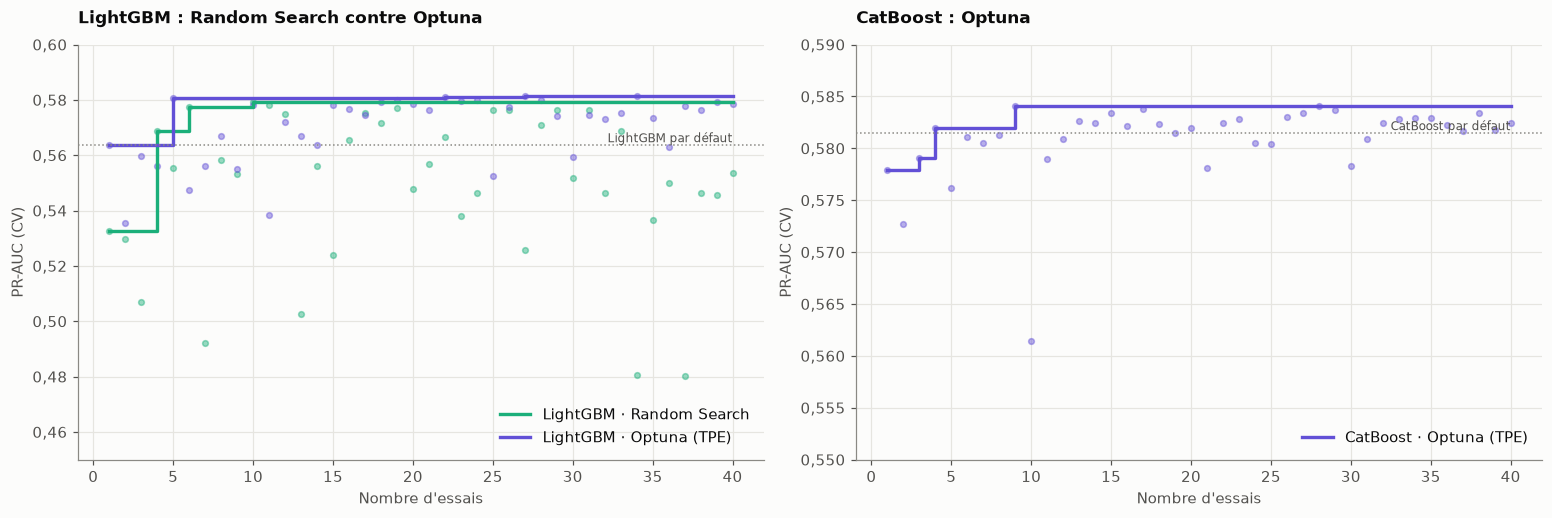

,LightGBM · Random Search,LightGBM · Optuna (TPE),CatBoost · Optuna (TPE)
après n essais,,,
1,0.5328,0.5636,0.5779
5,0.5686,0.5806,0.5820
10,0.5793,0.5806,0.5841
20,0.5793,0.5806,0.5841
40,0.5793,0.5815,0.5841


In [11]:
curves7 = {
    "LightGBM · Random Search": rs.cv_results_["mean_test_score"],
    "LightGBM · Optuna (TPE)": np.array([t.value for t in study_lgbm.trials]),
    "CatBoost · Optuna (TPE)": np.array([t.value for t in study_cat.trials]),
}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
trial = np.arange(1, 41)
for name, color in [("LightGBM · Random Search", viz.COMPOSITION[0]), ("LightGBM · Optuna (TPE)", viz.COMPOSITION[1])]:
    scores = curves7[name]
    axes[0].scatter(trial, scores, color=color, s=14, alpha=0.45)
    axes[0].step(trial, np.maximum.accumulate(scores), where="post", color=color, lw=2.2, label=name)
axes[0].axhline(summary7.loc["LightGBM · défaut", ("pr_auc", "val", "mean")], color=viz.INK_3, ls=":", lw=1)
axes[0].annotate(" LightGBM par défaut", (40, summary7.loc["LightGBM · défaut", ("pr_auc", "val", "mean")]), ha="right", va="bottom", fontsize=8, color=viz.INK_2)
axes[0].set(title="LightGBM : Random Search contre Optuna", ylim=(0.45, 0.6))
scores = curves7["CatBoost · Optuna (TPE)"]
axes[1].scatter(trial, scores, color=viz.COMPOSITION[1], s=14, alpha=0.45)
axes[1].step(trial, np.maximum.accumulate(scores), where="post", color=viz.COMPOSITION[1], lw=2.2, label="CatBoost · Optuna (TPE)")
axes[1].axhline(summary7.loc["CatBoost · défaut", ("pr_auc", "val", "mean")], color=viz.INK_3, ls=":", lw=1)
axes[1].annotate(" CatBoost par défaut", (40, summary7.loc["CatBoost · défaut", ("pr_auc", "val", "mean")]), ha="right", va="bottom", fontsize=8, color=viz.INK_2)
axes[1].set(title="CatBoost : Optuna", ylim=(0.55, 0.59))
for ax, digits in zip(axes, [2, 3]):
    ax.set(xlabel="Nombre d'essais", ylabel="PR-AUC (CV)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _, d=digits: viz.fr(f"{v:.{d}f}")))
    ax.legend(loc="lower right")
viz.save(fig, "07_historique_recherche")
plt.show()

pd.DataFrame({name: np.maximum.accumulate(s)[[0, 4, 9, 19, 39]] for name, s in curves7.items()},
             index=pd.Index([1, 5, 10, 20, 40], name="après n essais")).round(4)

**Réponse Q7.3.** Points : score de chaque essai ; courbe en escalier : meilleur score obtenu jusque-là.

- **Optuna progresse plus vite ici.** Dès le 5ᵉ essai, il atteint 0,581, mieux que ce que la Random Search trouve en 40 essais (0,579, atteint au 10ᵉ). Ses essais se concentrent ensuite dans la zone prometteuse : beaucoup de points au-dessus de 0,57, quand la Random Search continue d'essayer des configurations médiocres (jusqu'à 0,47).
- **Mais l'écart final est minuscule** (0,5815 contre 0,5793, soit 0,1 écart-type) et les deux recherches plafonnent après une dizaine d'essais : sur cet espace, beaucoup de configurations se valent.
- **Prudence (slides 47–48)** : une seule graine, un seul jeu de données, 40 essais. Avec une autre graine, la Random Search aurait pu tirer une bonne configuration plus tôt, ou TPE explorer moins bien. Pour conclure qu'Optuna est meilleur *en général*, il faudrait répéter l'expérience avec plusieurs graines et comparer les courbes moyennes. La slide 47 rappelle d'ailleurs que 60 tirages au hasard ont 95 % de chances de tomber dans le top 5 % : avec un budget suffisant, la Random Search est un adversaire sérieux.

### Q7.4 · `best_score_` est-il une estimation honnête ?

In [12]:
# Nested CV (slide 29) : la recherche aléatoire (40 essais, CV interne à 3 plis) est refaite dans
# chaque pli externe ; le pli externe, jamais vu par la recherche, mesure la procédure complète.
inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=RS)
inner_search = RandomizedSearchCV(lgbm_base, space, n_iter=40, cv=inner, scoring="average_precision",
                                  random_state=RS, n_jobs=-1)
t0 = time.time()
nested = cross_val_score(inner_search, X_train, y_train, cv=CV, scoring="average_precision")
time_nested = time.time() - t0
pd.DataFrame({
    "estimation": ["best_score_ (Random Search)", "best_value (Optuna)", "nested CV (Random Search)"],
    "PR-AUC": [rs.best_score_, study_lgbm.best_value, nested.mean()],
    "écart-type": [rs.cv_results_["std_test_score"][rs.best_index_], np.nan, nested.std()],
    "temps (s)": [time_rs, time_op_lgbm, time_nested],
}).set_index("estimation").round(4)

,PR-AUC,écart-type,temps (s)
estimation,,,
best_score_ (Random Search),0.5793,0.0252,50.8252
best_value (Optuna),0.5815,NaN,43.8819
nested CV (Random Search),0.5785,0.0246,72.1542


**Réponse Q7.4.** **Non, `best_score_` est optimiste.** C'est le **maximum** de 40 scores de validation croisée, calculés sur les mêmes plis. Chaque score contient une part de chance (le hasard du découpage) ; en prenant le meilleur, on sélectionne aussi la configuration la plus chanceuse sur *ces* plis. C'est exactement le piège des comparaisons multiples de la slide 24 : le « meilleur » de 100 modèles aléatoires paraît bon alors qu'il n'a rien appris. Les plis de validation ont servi à **choisir** : ils ne peuvent plus servir à **mesurer**.

**Estimation honnête (slide 29) : la nested CV.** Une boucle **interne** (3 plis) choisit les hyperparamètres ; une boucle **externe** (nos 5 plis) mesure la procédure complète « réglage + entraînement » sur des lignes que la recherche n'a jamais vues. Ici : **0,579 ± 0,025**, contre 0,579 pour `best_score_` et 0,5815 pour Optuna. L'optimisme est **faible** sur ce jeu (environ 0,001 à 0,003) : beaucoup de configurations se valent, la sélection gagne donc peu sur la chance. Mais il est réel, et il serait bien plus grand avec un petit jeu ou un grand espace de recherche.

La nested CV estime une **procédure**, pas un modèle précis. La mesure finale du modèle retenu se fera **une seule fois sur le test** (étape 10).

### Q7.5 · Quels hyperparamètres comptent le plus ?

,LightGBM,CatBoost
num_leaves,0.375,NaN
colsample_bytree,0.316,NaN
learning_rate,0.119,0.122
subsample,0.081,NaN
reg_lambda,0.076,NaN
min_child_samples,0.028,NaN
n_estimators,0.005,NaN
depth,NaN,0.514
l2_leaf_reg,NaN,0.151
bagging_temperature,NaN,0.138


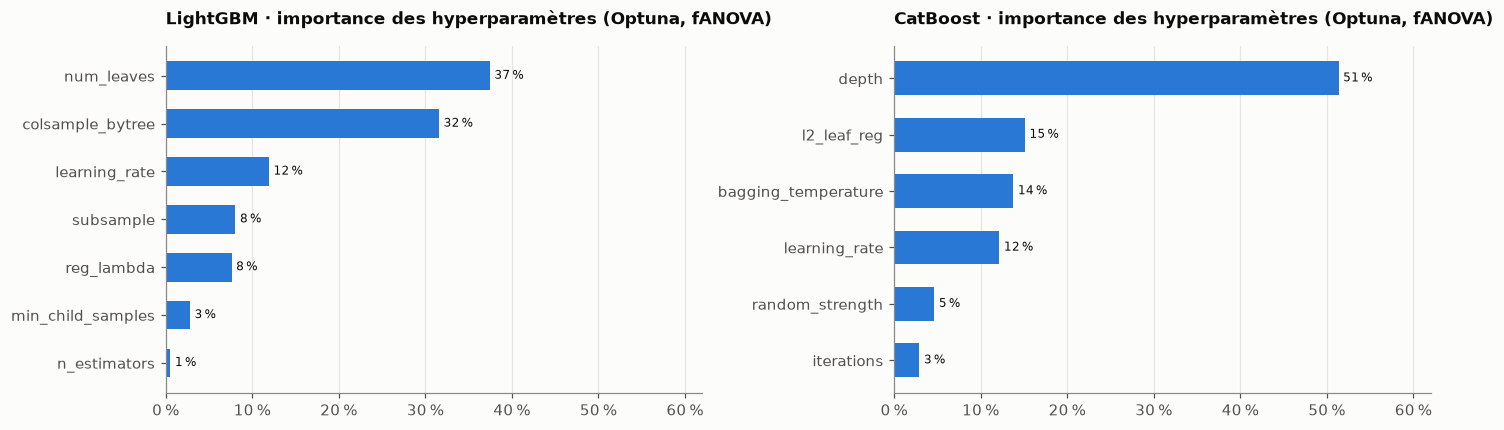

In [13]:
imp = pd.concat({
    "LightGBM": pd.Series(optuna.importance.get_param_importances(study_lgbm)),
    "CatBoost": pd.Series(optuna.importance.get_param_importances(study_cat)),
}, axis=1)
display(imp.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
for ax, name in zip(axes, imp.columns):
    s = imp[name].dropna().sort_values()
    ax.barh(s.index, s.to_numpy(), color=viz.YES, height=0.6)
    for yi, v in enumerate(s.to_numpy()):
        ax.annotate(viz.fmt_pct(v, 0), (v, yi), xytext=(3, 0), textcoords="offset points", va="center", fontsize=8)
    ax.set(title=f"{name} · importance des hyperparamètres (Optuna, fANOVA)", xlim=(0, 0.62))
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: viz.fmt_pct(v, 0)))
    ax.grid(axis="y", visible=False)
viz.save(fig, "07_importances_hyperparametres")
plt.show()

**Réponse Q7.5.** (`optuna.importance.get_param_importances`, la fonction utilisée par `plot_param_importances` : part de la variance du score expliquée par chaque hyperparamètre, méthode fANOVA.)

- **LightGBM** : `num_leaves` (≈ 37 %) et `colsample_bytree` (≈ 32 %) dominent, puis `learning_rate` (≈ 12 %) ; `min_child_samples` et `n_estimators` comptent très peu.
- **CatBoost** : `depth` domine (≈ 51 %) ; `l2_leaf_reg`, `bagging_temperature` et `learning_rate` se partagent le reste ; `iterations` ne compte presque pas.

**Cohérent avec Bergstra et Bengio (slide 47)** : sur 7 ou 6 dimensions, **deux ou trois seulement comptent vraiment**. C'est l'argument en faveur de la Random Search contre la grille : avec le même budget, le hasard explore 40 valeurs différentes de chaque hyperparamètre important, quand une grille n'en verrait que 2 ou 3. Dans les deux modèles, ce qui compte est la **complexité des arbres** (nombre de feuilles, profondeur), c'est-à-dire le curseur biais–variance de l'étape 5. Le nombre d'arbres compte peu dans cet espace, ce qui va dans le sens de la slide 51 (le fixer grand, avec arrêt anticipé).

### Bonus · `HalvingRandomSearchCV` (slide 50)

Successive Halving : 40 configurations commencent avec peu de lignes ; à chaque tour, on garde le meilleur tiers et on triple les lignes. **Attention au réglage** : avec les valeurs par défaut, le premier tour n'utilise que 20 lignes et le dernier 540, jamais toutes les données ; 20 lignes avec 14 % de positifs ne permettent pas de classer quoi que ce soit (essai : PR-AUC 0,25). `min_resources="exhaust"` choisit le budget de départ pour que le dernier tour utilise **tout** `X_train`.

In [14]:
t0 = time.time()
halving = HalvingRandomSearchCV(lgbm_base, space, n_candidates=40, factor=3, resource="n_samples",
                                min_resources="exhaust", cv=CV, scoring="average_precision",
                                random_state=RS, n_jobs=-1)
halving.fit(X_train, y_train)
time_halving = time.time() - t0
display(pd.DataFrame({"lignes par configuration": halving.n_resources_, "configurations": halving.n_candidates_},
                     index=pd.Index(range(1, halving.n_iterations_ + 1), name="tour")))
pd.DataFrame({
    "PR-AUC (meilleur score)": [rs.best_score_, halving.best_score_],
    "temps (s)": [time_rs, time_halving],
}, index=["RandomizedSearchCV (40 × toutes les lignes)", "HalvingRandomSearchCV (40 → 14 → 5 → 2)"]).round(4)

,lignes par configuration,configurations
tour,,
1,697,40
2,2091,14
3,6273,5
4,18819,2


,PR-AUC (meilleur score),temps (s)
RandomizedSearchCV (40 × toutes les lignes),0.5793,50.8252
HalvingRandomSearchCV (40 → 14 → 5 → 2),0.5772,14.6363


**Lecture.** La recherche par élimination atteint presque le même score (≈ 0,577 contre 0,579) en **3 à 4 fois moins de temps** : la plupart des 40 configurations sont éliminées après un entraînement sur ≈ 700 lignes. Le risque est d'éliminer trop tôt une configuration qui n'est bonne qu'avec beaucoup de données (par exemple un pas d'apprentissage lent). Utile quand chaque essai coûte cher (CatBoost) ; pour LightGBM, à moins d'une seconde l'essai, le gain de temps compte peu. La nested CV (Q7.4) complète le bonus.

### Synthèse · les candidats réglés face au modèle de base

In [15]:
final = ["Régression logistique (modèle de base)", "LightGBM · Optuna", "CatBoost · Optuna"]
display(format_summary(summary7.loc[final], metrics=["pr_auc", "roc_auc", "brier", "logloss", "recall_t", "cost_t"]))
pd.DataFrame({
    "LightGBM réglé − modèle de base": paired_difference(res[final[0]], res[final[1]]),
    "CatBoost réglé − modèle de base": paired_difference(res[final[0]], res[final[2]]),
    "CatBoost réglé − LightGBM réglé": paired_difference(res[final[1]], res[final[2]]),
}).T[["différence moyenne B − A", "erreur-type des différences", "plis où B > A"]].round(4)

,pr_auc,roc_auc,brier,logloss,recall_t,cost_t,temps (s)
Régression logistique (modèle de base),0.561 ± 0.026,0.849 ± 0.010,0.087 ± 0.003,0.292 ± 0.009,0.852 ± 0.011,0.259 ± 0.006,0.23
LightGBM · Optuna,0.581 ± 0.024,0.861 ± 0.010,0.085 ± 0.003,0.283 ± 0.009,0.852 ± 0.020,0.244 ± 0.012,0.62
CatBoost · Optuna,0.584 ± 0.027,0.863 ± 0.010,0.084 ± 0.002,0.282 ± 0.008,0.846 ± 0.016,0.241 ± 0.011,10.03


,différence moyenne B − A,erreur-type des différences,plis où B > A
LightGBM réglé − modèle de base,0.0210,0.0034,5.0
CatBoost réglé − modèle de base,0.0236,0.0050,5.0
CatBoost réglé − LightGBM réglé,0.0027,0.0022,4.0


**Synthèse de l'étape 7.**

| Modèle | PR-AUC (CV) | Entraînement | Temps / pli |
|---|---|---|---|
| Régression logistique (modèle de base) | 0,561 ± 0,026 | 0,566 | 0,2 s |
| **LightGBM réglé** (Optuna) | **0,581 ± 0,024** | 0,615 | 0,6 s |
| **CatBoost réglé** (Optuna) | **0,584 ± 0,027** | 0,621 | ≈ 11 s |

- Le réglage a **beaucoup aidé LightGBM** (+0,8 écart-type, surapprentissage corrigé) et **presque rien apporté à CatBoost** (+0,1 écart-type), déjà bien réglé par défaut.
- Les deux candidats réglés font **jeu égal** (écart de 0,003, inférieur à l'écart-type) et battent le modèle de base dans les 5 plis, de **moins d'un écart-type** (+0,021 et +0,024).
- L'estimation honnête de la procédure (nested CV) est 0,579 : l'optimisme de `best_score_` est faible ici.
- Les configurations sont enregistrées dans `models.py` (`make_lgbm()`, `make_catboost()`).
- **Étape 8** : on compare la **calibration** des deux candidats et du modèle de base ; le choix final se fera sur la calibration et le coût métier, puisque la PR-AUC ne les départage pas.